## 선형회귀 모델 실습

In [5]:
# prompt: boston_train.csv 파일을 읽어서 ‘RM’ 컬럼만 피처로 사용하여 단항 회귀 모델을 만들어줘.평가지표도 구해줘

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Load the dataset
df = pd.read_csv('boston_train.csv')

# Select the feature 'RM' and the target variable (assuming 'MEDV' is the target)
X = df[['RM']]
y = df['MEDV']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create a linear regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2}")


Mean Squared Error: 39.24181745786426
R-squared: 0.47479007982276655


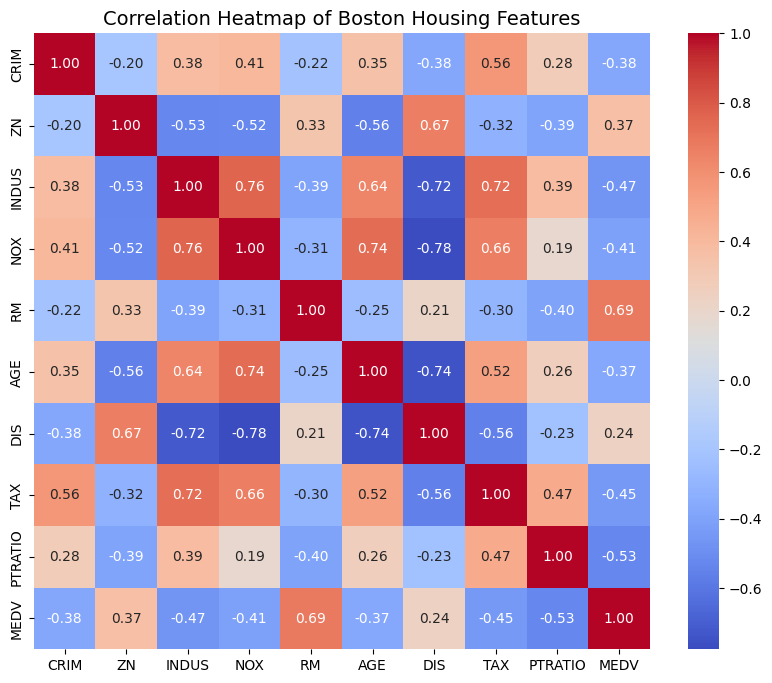

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# 상관관계 행렬 계산 (학습 데이터셋 기준)
corr_matrix = df.corr()

# 히트맵 시각화
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)
plt.title('Correlation Heatmap of Boston Housing Features', fontsize=14)
plt.show()

In [4]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 1. 학습 및 테스트 데이터 분리 (모든 피처 사용)
X_train = df.drop(columns=['MEDV'])
y_train = df['MEDV']

X_test = test_df.drop(columns=['MEDV'])
y_test = test_df['MEDV']

# 2. 다항 회귀 파이프라인 구성 (degree=2 다항 피처 확장 + 선형 회귀)
poly_model = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('linear', LinearRegression())
])

# 3. 모델 학습
poly_model.fit(X_train, y_train)

# 4. 테스트 데이터 예측 및 평가
y_pred_poly = poly_model.predict(X_test)

mse_poly = mean_squared_error(y_test, y_pred_poly)
rmse_poly = np.sqrt(mse_poly)
mae_poly = mean_absolute_error(y_test, y_pred_poly)
r2_poly = r2_score(y_test, y_pred_poly)

print("=== 다항 회귀 (Degree=2, 전 피처) 평가 지표 ===")
print(f"MAE: {mae_poly:.4f}")
print(f"MSE: {mse_poly:.4f}")
print(f"RMSE: {rmse_poly:.4f}")
print(f"R2 Score: {r2_poly:.4f}")


=== 다항 회귀 (Degree=2, 전 피처) 평가 지표 ===
MAE: 2.4116
MSE: 10.6554
RMSE: 3.2643
R2 Score: 0.8103


### Boston 주택가격: XGBoost 기반 다항 회귀 모델 실습

=== Boston 주택가격 XGBoost 다항 회귀 (Degree=2) 평가 지표 ===
MAE  (Mean Absolute Error)     : 2.0664
MSE  (Mean Squared Error)      : 8.7856
RMSE (Root Mean Squared Error) : 2.9641
R2 Score (결정계수)            : 0.8436


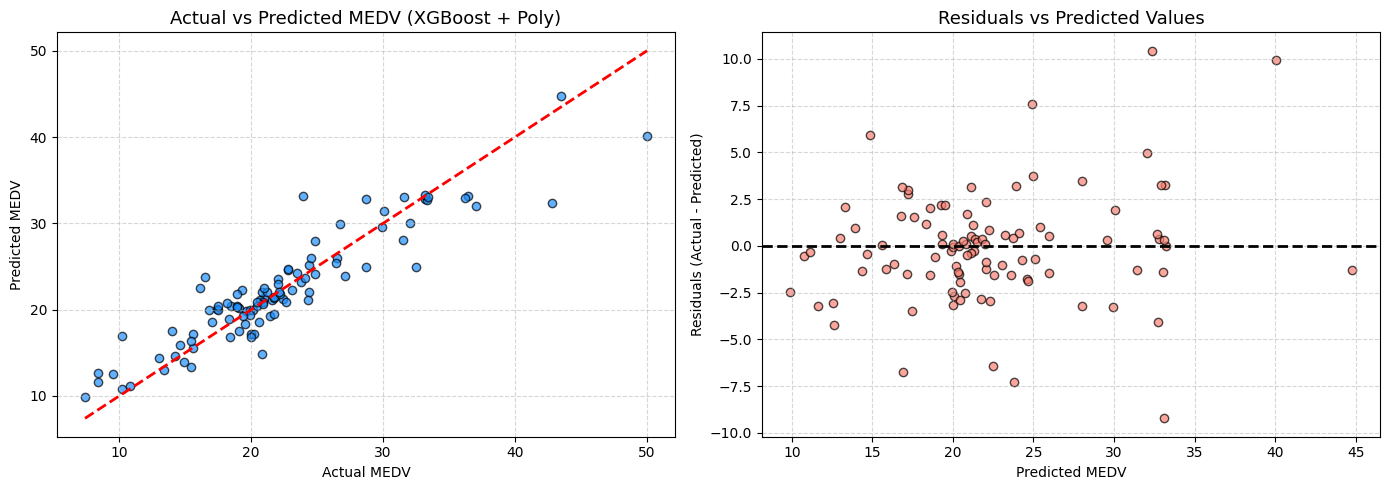

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

# 1. 학습 및 테스트 데이터 로드
train_df = pd.read_csv('boston_train.csv')
test_df = pd.read_csv('boston_test.csv')

# 피처와 타깃(MEDV) 분리
X_train = train_df.drop(columns=['MEDV'])
y_train = train_df['MEDV']

X_test = test_df.drop(columns=['MEDV'])
y_test = test_df['MEDV']

# 2. 다항 피처 확장(degree=2) + XGBRegressor 파이프라인 구성
xgb_poly_model = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('xgb', XGBRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=4,
        random_state=42
    ))
])

# 3. 모델 학습
xgb_poly_model.fit(X_train, y_train)

# 4. 테스트 데이터 예측 및 평가
y_pred_xgb = xgb_poly_model.predict(X_test)

mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print("=== Boston 주택가격 XGBoost 다항 회귀 (Degree=2) 평가 지표 ===")
print(f"MAE  (Mean Absolute Error)     : {mae_xgb:.4f}")
print(f"MSE  (Mean Squared Error)      : {mse_xgb:.4f}")
print(f"RMSE (Root Mean Squared Error) : {rmse_xgb:.4f}")
print(f"R2 Score (결정계수)            : {r2_xgb:.4f}")

# 5. 시각화 (실제값 vs 예측값 산점도 & 잔차 분석)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 산점도
axes[0].scatter(y_test, y_pred_xgb, color='dodgerblue', alpha=0.7, edgecolors='k')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title('Actual vs Predicted MEDV (XGBoost + Poly)', fontsize=13)
axes[0].set_xlabel('Actual MEDV')
axes[0].set_ylabel('Predicted MEDV')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 잔차(Residuals) 분포
residuals = y_test - y_pred_xgb
axes[1].scatter(y_pred_xgb, residuals, color='salmon', alpha=0.7, edgecolors='k')
axes[1].axhline(y=0, color='black', linestyle='--', lw=2)
axes[1].set_title('Residuals vs Predicted Values', fontsize=13)
axes[1].set_xlabel('Predicted MEDV')
axes[1].set_ylabel('Residuals (Actual - Predicted)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [20]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the test dataset
test_df = pd.read_csv('boston_test.csv')

# Prepare test feature and target
X_test = test_df[['RM']]
y_test = test_df['MEDV']

# Predict using the trained model
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("=== 평가 지표 ===")
print(f"MAE (Mean Absolute Error): {mae:.4f}")
print(f"MSE (Mean Squared Error): {mse:.4f}")
print(f"RMSE (Root Mean Squared Error): {rmse:.4f}")
print(f"R2 Score (결정계수): {r2:.4f}")


=== 평가 지표 ===
MAE (Mean Absolute Error): 3.5611
MSE (Mean Squared Error): 25.6845
RMSE (Root Mean Squared Error): 5.0680
R2 Score (결정계수): 0.5427


### 이진 분류 모델 구현 실습

=== 데이터 크기 (Shape) ===
(569, 31)

=== 결측치 및 데이터 타입 ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



타겟 컬럼: target
target
1    357
0    212
Name: count, dtype: int64

비율 (%):
target
1    62.741652
0    37.258348
Name: proportion, dtype: float64


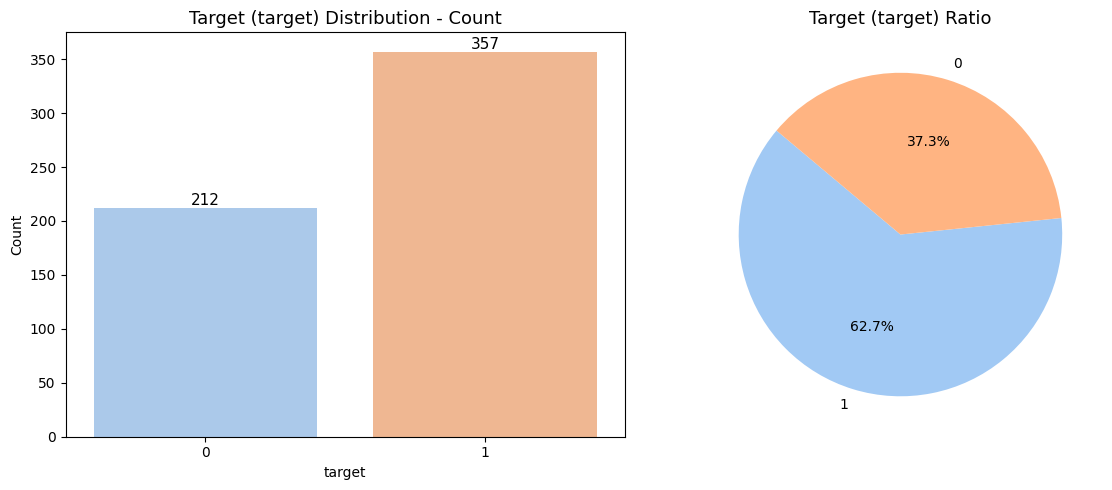

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 데이터 불러오기
file_path = '/content/Breast Cancer.csv'
bc_df = pd.read_csv(file_path)

# 2. 데이터 기본 정보 출력
print("=== 데이터 크기 (Shape) ===")
print(bc_df.shape)
print("\n=== 결측치 및 데이터 타입 ===")
print(bc_df.info())
print("\n=== 상위 5개 행 ===")
display(bc_df.head())

# target 컬럼 후보 탐색 (보통 'diagnosis' 또는 'target')
target_col = None
for col in ['diagnosis', 'target', 'class']:
    if col in bc_df.columns:
        target_col = col
        break
if not target_col:
    target_col = bc_df.columns[-1]

print(f"\n타겟 컬럼: {target_col}")
print(bc_df[target_col].value_counts())
print(f"\n비율 (%):\n{bc_df[target_col].value_counts(normalize=True) * 100}")

# 3. Target 분포 시각화
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 막대 그래프 (Countplot)
sns.countplot(x=target_col, data=bc_df, palette='pastel', ax=axes[0], hue=target_col, legend=False)
axes[0].set_title(f'Target ({target_col}) Distribution - Count', fontsize=13)
axes[0].set_ylabel('Count')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11)

# 파이 차트 (Pie chart)
counts = bc_df[target_col].value_counts()
axes[1].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
axes[1].set_title(f'Target ({target_col}) Ratio', fontsize=13)

plt.tight_layout()
plt.show()

=== 결정 트리 분류 모델 평가지표 ===
Accuracy  (정확도) : 0.9386
Precision (정밀도) : 0.9577
Recall    (재현율) : 0.9444
F1 Score  (F1점수) : 0.9510
ROC-AUC   (곡선하면적): 0.9342

=== Classification Report ===
               precision    recall  f1-score   support

Malignant (0)       0.91      0.93      0.92        42
   Benign (1)       0.96      0.94      0.95        72

     accuracy                           0.94       114
    macro avg       0.93      0.94      0.93       114
 weighted avg       0.94      0.94      0.94       114



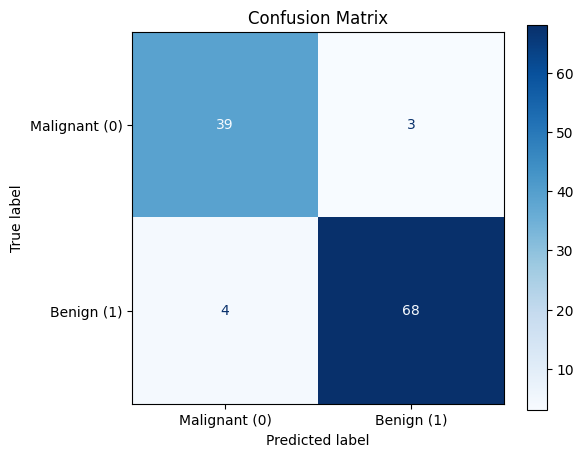

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. 특성(X)과 타깃(y) 분리
X = bc_df.drop(columns=['target'])
y = bc_df['target']

# 2. 학습 및 테스트 데이터 분리 (계층적 샘플링 적용)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. 결정 트리 모델 생성 및 학습
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)

# 4. 예측 수행
y_pred = dt_model.predict(X_test)
y_pred_proba = dt_model.predict_proba(X_test)[:, 1]

# 5. 평가지표 계산
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("=== 결정 트리 분류 모델 평가지표 ===")
print(f"Accuracy  (정확도) : {accuracy:.4f}")
print(f"Precision (정밀도) : {precision:.4f}")
print(f"Recall    (재현율) : {recall:.4f}")
print(f"F1 Score  (F1점수) : {f1:.4f}")
print(f"ROC-AUC   (곡선하면적): {roc_auc:.4f}")
print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=['Malignant (0)', 'Benign (1)']))

# 6. 혼동 행렬 시각화
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Malignant (0)', 'Benign (1)'])
disp.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix')
plt.show()

### 다중 분류 모델 구현 실습

=== 데이터셋 기본 정보 ===


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),label
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0



=== 라벨('label') 분포 수치 ===


,Count,Percentage (%)
label,,
0,50,33.33
1,50,33.33
2,50,33.33


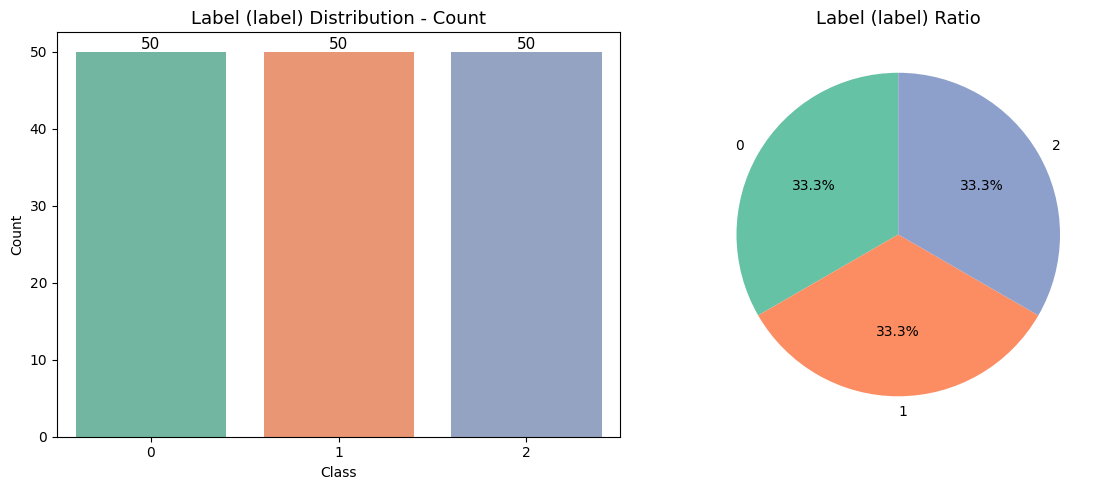

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 데이터 불러오기
iris_df = pd.read_csv('/content/iris.csv')

print("=== 데이터셋 기본 정보 ===")
display(iris_df.head())

# 2. 라벨 컬럼 탐색
label_col = None
for col in ['species', 'target', 'label', 'class', 'variety']:
    if col in iris_df.columns:
        label_col = col
        break
if not label_col:
    label_col = iris_df.columns[-1]

# 3. 라벨 분포 수치 확인
counts = iris_df[label_col].value_counts()
proportions = iris_df[label_col].value_counts(normalize=True) * 100

dist_df = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': proportions.round(2)
})

print(f"\n=== 라벨('{label_col}') 분포 수치 ===")
display(dist_df)

# 4. 라벨 분포 시각화
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 막대 그래프 (Countplot)
sns.countplot(x=label_col, data=iris_df, palette='Set2', ax=axes[0], hue=label_col, legend=False)
axes[0].set_title(f'Label ({label_col}) Distribution - Count', fontsize=13)
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11)

# 파이 차트 (Pie chart)
axes[1].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('Set2'))
axes[1].set_title(f'Label ({label_col}) Ratio', fontsize=13)

plt.tight_layout()
plt.show()

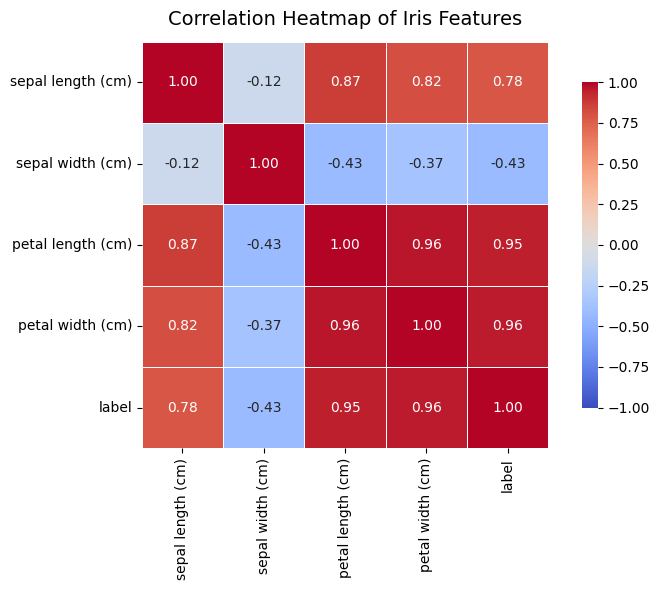

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 상관관계 행렬 계산
corr_matrix = iris_df.corr()

# 2. 히트맵 시각화 (수치 표시)
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)
plt.title('Correlation Heatmap of Iris Features', fontsize=14, pad=12)
plt.tight_layout()
plt.show()

=== 다중 분류 모델 평가 지표 (Random Forest) ===
Accuracy  (정확도)       : 0.9000
Precision (정밀도, macro): 0.9024
Recall    (재현율, macro): 0.9000
F1-Score  (F1점수, macro): 0.8997

=== Classification Report ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.82      0.90      0.86        10
           2       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



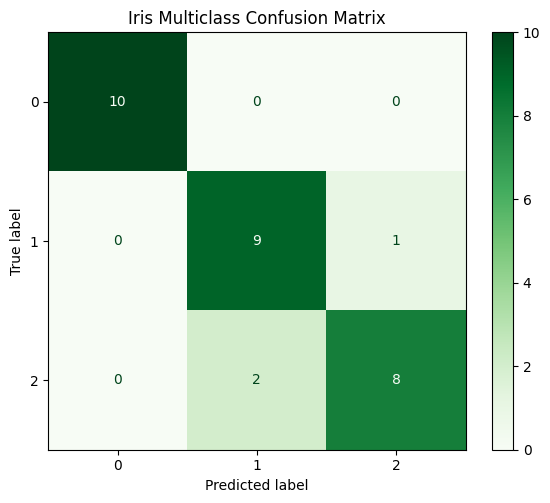

In [10]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

# 1. 특성(X)과 라벨(y) 분리
X = iris_df.drop(columns=['label'])
y = iris_df['label']

# 2. 학습용/테스트용 데이터 분리 (계층적 샘플링 적용)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. 다중 분류 모델 학습 (랜덤 포레스트 분류기)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 4. 예측 수행
y_pred = rf_model.predict(X_test)

# 5. 다중 분류 평가지표 계산 (macro 및 weighted 평균)
acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro')
rec_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')

print("=== 다중 분류 모델 평가 지표 (Random Forest) ===")
print(f"Accuracy  (정확도)       : {acc:.4f}")
print(f"Precision (정밀도, macro): {prec_macro:.4f}")
print(f"Recall    (재현율, macro): {rec_macro:.4f}")
print(f"F1-Score  (F1점수, macro): {f1_macro:.4f}")

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred))

# 6. 혼동 행렬 (Confusion Matrix) 시각화
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=rf_model.classes_)
disp.plot(cmap='Greens', ax=ax)
plt.title('Iris Multiclass Confusion Matrix')
plt.tight_layout()
plt.show()

### 앙상블 모델 구현 실습

타깃 클래스 매핑: {0: 'e', 1: 'p'}

=== Random Forest 이진 분류 평가지표 ===
Accuracy  (정확도) : 1.0000
Precision (정밀도) : 1.0000
Recall    (재현율) : 1.0000
F1 Score  (F1점수) : 1.0000
ROC-AUC   (곡선하면적): 1.0000

=== Classification Report ===
              precision    recall  f1-score   support

       e (0)       1.00      1.00      1.00       842
       p (1)       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



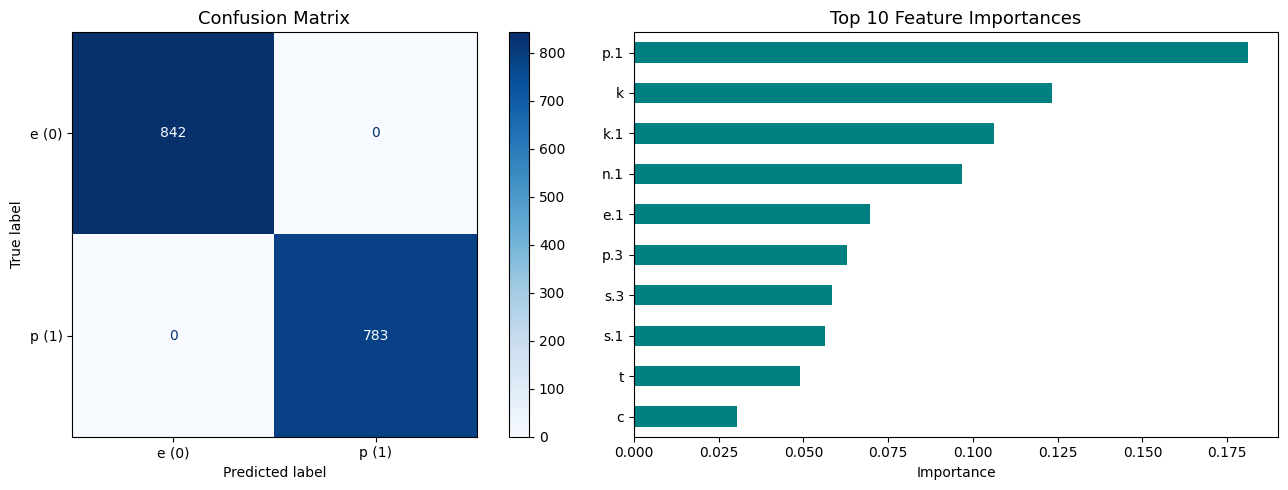

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. 데이터 불러오기 및 타깃 설정
mushroom_df = pd.read_csv('/content/mushroom.csv')
target_col = 'class' if 'class' in mushroom_df.columns else mushroom_df.columns[0]

# 2. 범주형 변수 레이블 인코딩
df_encoded = mushroom_df.copy()
label_encoders = {}

for col in df_encoded.columns:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le

# 3. 특성(X)과 타깃(y) 분리
X = df_encoded.drop(columns=[target_col])
y = df_encoded[target_col]

# 타깃 레이블 매핑 확인
classes_mapping = dict(enumerate(label_encoders[target_col].classes_))
print(f"타깃 클래스 매핑: {classes_mapping}")

# 4. 학습/테스트 데이터셋 분할 (8:2, 계층적 샘플링)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. RandomForest 이진 분류 모델 학습
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_train)

# 6. 예측 및 확률 산출
y_pred = rf_clf.predict(X_test)
y_pred_proba = rf_clf.predict_proba(X_test)[:, 1]

# 7. 평가지표 계산
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("\n=== Random Forest 이진 분류 평가지표 ===")
print(f"Accuracy  (정확도) : {accuracy:.4f}")
print(f"Precision (정밀도) : {precision:.4f}")
print(f"Recall    (재현율) : {recall:.4f}")
print(f"F1 Score  (F1점수) : {f1:.4f}")
print(f"ROC-AUC   (곡선하면적): {roc_auc:.4f}")

print("\n=== Classification Report ===")
target_names = [f"{v} ({k})" for k, v in classes_mapping.items()]
print(classification_report(y_test, y_pred, target_names=target_names))

# 8. 시각화 (혼동 행렬 & 특성 중요도)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 혼동 행렬 시각화
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix', fontsize=13)

# 상위 10개 피처 중요도 시각화
importances = pd.Series(rf_clf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
importances.plot(kind='barh', ax=axes[1], color='teal')
axes[1].invert_yaxis()
axes[1].set_title('Top 10 Feature Importances', fontsize=13)
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()

=== 데이터 크기 (Shape) ===
(8123, 23)

=== 상위 5개 행 ===


,p,x,s,n,t,p.1,f,c,n.1,k,...,s.2,w,w.1,p.2,w.2,o,p.3,k.1,s.3,u
0,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
1,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
2,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
3,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g
4,e,x,y,y,t,a,f,c,b,n,...,s,w,w,p,w,o,p,k,n,g



타깃 컬럼: 'p'

=== 타깃 라벨 분포 수치 ===


,Count,Ratio (%)
p,,
e,4208,51.8
p,3915,48.2


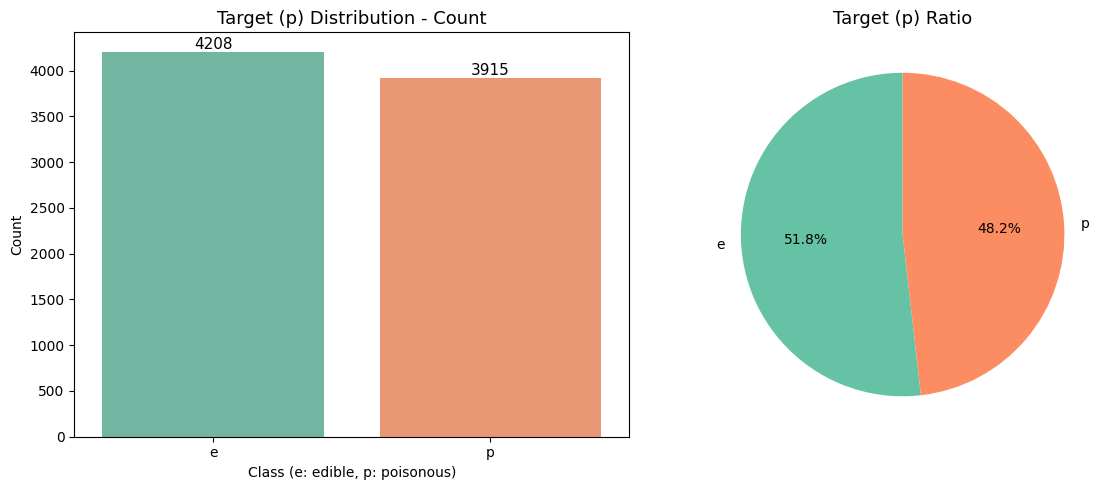

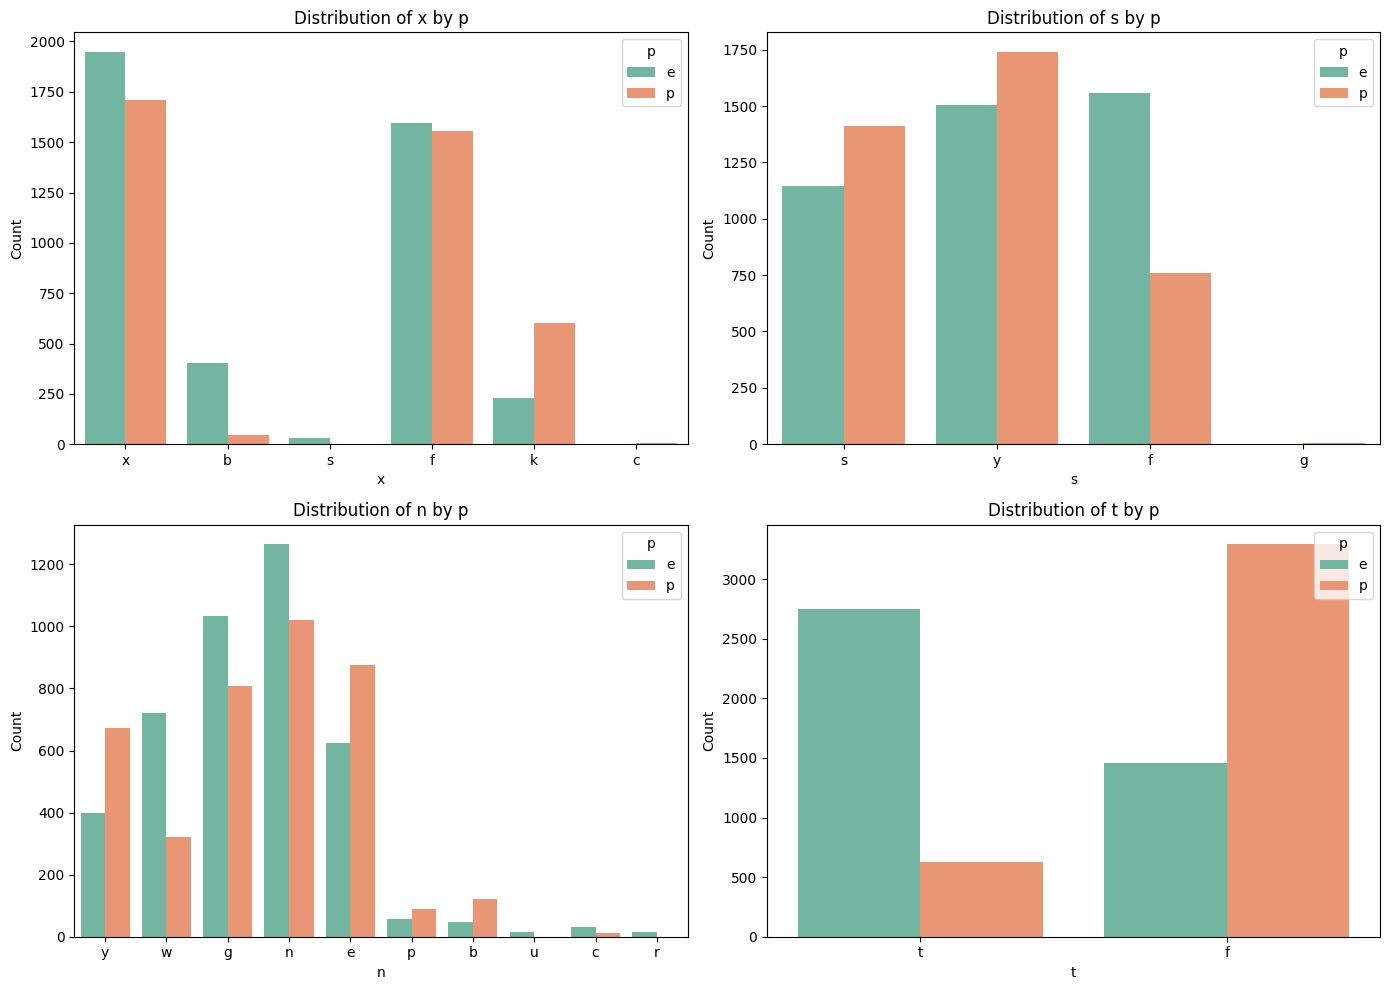

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 독버섯 데이터 불러오기
mushroom_df = pd.read_csv('/content/mushroom.csv')

print("=== 데이터 크기 (Shape) ===")
print(mushroom_df.shape)
print("\n=== 상위 5개 행 ===")
display(mushroom_df.head())

# 2. 타깃 컬럼 확인 (일반적으로 첫 번째 열 또는 'class')
target_col = 'class' if 'class' in mushroom_df.columns else mushroom_df.columns[0]
print(f"\n타깃 컬럼: '{target_col}'")

# 타깃 분포 수치 확인
target_counts = mushroom_df[target_col].value_counts()
target_ratios = mushroom_df[target_col].value_counts(normalize=True) * 100
print("\n=== 타깃 라벨 분포 수치 ===")
dist_df = pd.DataFrame({'Count': target_counts, 'Ratio (%)': target_ratios.round(2)})
display(dist_df)

# 3. 타깃 라벨 분포 시각화 (막대그래프 + 원형그래프)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x=target_col, data=mushroom_df, palette='Set2', ax=axes[0], hue=target_col, legend=False)
axes[0].set_title(f'Target ({target_col}) Distribution - Count', fontsize=13)
axes[0].set_xlabel('Class (e: edible, p: poisonous)')
axes[0].set_ylabel('Count')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11)

axes[1].pie(target_counts, labels=target_counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('Set2'))
axes[1].set_title(f'Target ({target_col}) Ratio', fontsize=13)
plt.tight_layout()
plt.show()

# 4. 주요 특징 컬럼 상위 4개에 대한 분포 시각화
feature_cols = [col for col in mushroom_df.columns if col != target_col][:4]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.countplot(x=col, hue=target_col, data=mushroom_df, palette='Set2', ax=axes[i])
    axes[i].set_title(f'Distribution of {col} by {target_col}', fontsize=12)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')
    axes[i].legend(title=target_col, loc='upper right')

plt.tight_layout()
plt.show()

=== XGBoost 이진 분류 모델 평가지표 ===
Accuracy  (정확도) : 1.0000
Precision (정밀도) : 1.0000
Recall    (재현율) : 1.0000
F1 Score  (F1점수) : 1.0000
ROC-AUC   (곡선하면적): 1.0000

=== Classification Report ===
              precision    recall  f1-score   support

       e (0)       1.00      1.00      1.00       842
       p (1)       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



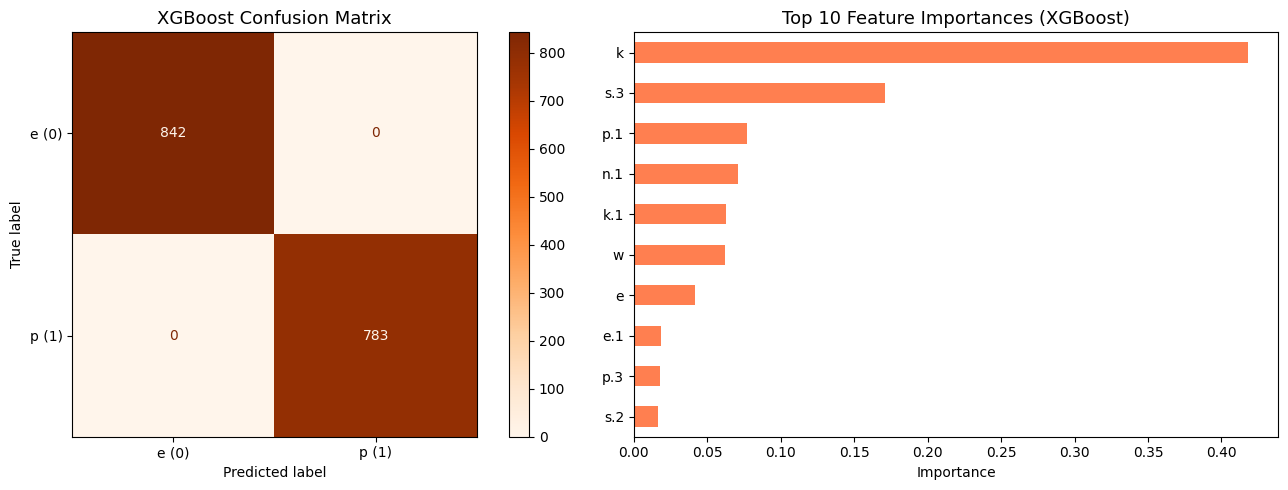

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from xgboost import XGBClassifier

# 1. XGBoost 이진 분류 모델 생성 및 학습
xgb_clf = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42,
    eval_metric='logloss'
)
xgb_clf.fit(X_train, y_train)

# 2. 예측 및 예측 확률 산출
y_pred_xgb = xgb_clf.predict(X_test)
y_pred_proba_xgb = xgb_clf.predict_proba(X_test)[:, 1]

# 3. 평가지표 계산
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_pred_proba_xgb)

print("=== XGBoost 이진 분류 모델 평가지표 ===")
print(f"Accuracy  (정확도) : {accuracy_xgb:.4f}")
print(f"Precision (정밀도) : {precision_xgb:.4f}")
print(f"Recall    (재현율) : {recall_xgb:.4f}")
print(f"F1 Score  (F1점수) : {f1_xgb:.4f}")
print(f"ROC-AUC   (곡선하면적): {roc_auc_xgb:.4f}")

print("\n=== Classification Report ===")
target_names = [f"{v} ({k})" for k, v in classes_mapping.items()]
print(classification_report(y_test, y_pred_xgb, target_names=target_names))

# 4. 시각화 (혼동 행렬 & 특성 중요도)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 혼동 행렬 시각화
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=target_names)
disp.plot(cmap='Oranges', ax=axes[0])
axes[0].set_title('XGBoost Confusion Matrix', fontsize=13)

# 상위 10개 특성 중요도 (Feature Importance)
importances_xgb = pd.Series(xgb_clf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
importances_xgb.plot(kind='barh', ax=axes[1], color='coral')
axes[1].invert_yaxis()
axes[1].set_title('Top 10 Feature Importances (XGBoost)', fontsize=13)
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()